<a href="https://colab.research.google.com/github/DobryCzlowiekDobryKodzik/Traffic-Sign-Recognition/blob/main/notebooks/etap_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etap 2 – Implementacja potoku przetwarzania obrazów


## 1. Wczytywanie danych

W pierwszym kroku przygotowano mechanizm automatycznego wczytywania zdjęć znaków drogowych z Dysku Google. Zdjęcia zostały podzielone na foldery odpowiadające rozpoznawanym znakom oraz pozostałym znakom drogowym.

In [1]:
from google.colab import drive
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:

DATA_DIR = Path('/content/drive/MyDrive/Zdjęcia-projekt')

In [3]:
# Etykiety rozpoznawanych znaków
klasy = {
    "stop": "B-20",
    "rondo": "C-12",
    "skrzyzowanie": "A-5",
    "inne": "Inny znak"
}

rozszerzenia = {".jpg", ".jpeg", ".png"}
dane = []

for folder, etykieta in klasy.items():
    sciezka_folderu = DATA_DIR / folder

    if not sciezka_folderu.exists():
        print(f"Brak folderu: {sciezka_folderu}")
        continue

    for plik in sorted(sciezka_folderu.rglob("*")):
        if plik.suffix.lower() not in rozszerzenia:
            continue

        obraz = cv2.imread(str(plik))

        if obraz is None:
            print(f"Nie udało się wczytać: {plik.name}")
            continue

        dane.append({
            "plik": plik.name,
            "sciezka": str(plik),
            "etykieta": etykieta,
            "szerokosc": obraz.shape[1],
            "wysokosc": obraz.shape[0]
        })

df_zdjecia = pd.DataFrame(dane)

print(f"Wczytano {len(df_zdjecia)} zdjęć.")
display(df_zdjecia)

Wczytano 36 zdjęć.


,plik,sciezka,etykieta,szerokosc,wysokosc
0,20261030_115146.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
1,20261030_115203.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
2,20261030_115314.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
3,20261104_162204.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
4,20261104_162218.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
5,20261104_162229.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
6,20261104_162239.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
7,20261104_162318.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
8,20261104_162326.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
9,20261030_115838.jpg,/content/drive/MyDrive/Zdjęcia-projekt/rondo/2...,C-12,6000,8000


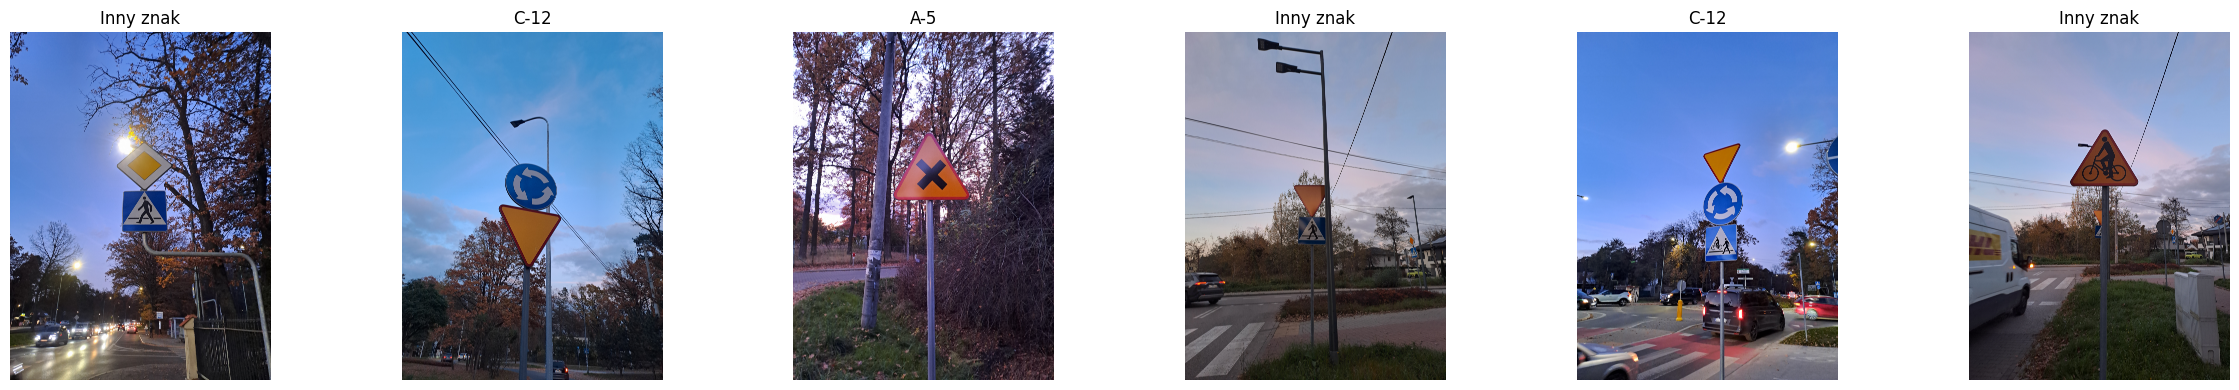

In [4]:
if len(df_zdjecia) > 0:
    probka = df_zdjecia.sample(
        n=min(6, len(df_zdjecia)),
        random_state=42
    )

    fig, axes = plt.subplots(
        1, len(probka),
        figsize=(4 * len(probka), 4),
        squeeze=False
    )

    for ax, (_, wiersz) in zip(axes[0], probka.iterrows()):
        obraz = cv2.imread(wiersz["sciezka"])
        obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)

        ax.imshow(obraz_rgb)
        ax.set_title(wiersz["etykieta"])
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Nie znaleziono zdjęć. Sprawdź ścieżkę DATA_DIR.")

## 2. Przetwarzanie wstępne obrazów

Celem przetwarzania wstępnego jest przygotowanie obrazów do dalszej segmentacji i ekstrakcji cech znaków drogowych. Zastosowano następujące operacje:

1. **Skalowanie proporcjonalne** – zmniejszenie rozdzielczości obrazów z zachowaniem ich oryginalnych proporcji. Maksymalny wymiar obrazu ustalono na 800 pikseli.
2. **Filtracja Gaussa** – zastosowanie filtra o rozmiarze 5×5 w celu redukcji szumów i niewielkich zakłóceń obrazu.
3. **Korekcja kontrastu CLAHE (opcjonalnie)** – lokalne wyrównanie kontrastu w kanale jasności przestrzeni Lab, poprawiające widoczność szczegółów w nierównomiernych warunkach oświetlenia.

Zastosowanie CLAHE będzie oceniane na podstawie porównania wyników przetwarzania i segmentacji obrazów.

In [5]:
def skaluj_proporcjonalnie(obraz, max_wymiar=800):
    h, w = obraz.shape[:2]

    # Zachowanie proporcji i unikanie powiększania małych obrazów
    skala = min(max_wymiar / max(h, w), 1.0)

    nowa_szerokosc = max(1, int(round(w * skala)))
    nowa_wysokosc = max(1, int(round(h * skala)))

    return cv2.resize(
        obraz,
        (nowa_szerokosc, nowa_wysokosc),
        interpolation=cv2.INTER_AREA
    )


def przetwarzanie_wstepne(obraz, prog_jasnosci = 80):
    # 1. Skalowanie proporcjonalne
    obraz = skaluj_proporcjonalnie(obraz)

    # 2. Filtr Gaussa 5x5
    obraz = cv2.GaussianBlur(obraz, (5, 5), 0)

    # 3. Opcjonalna korekcja kontrastu CLAHE

    lab = cv2.cvtColor(obraz, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    median = np.median(l)
    procent_ciemnych = np.mean(l < 50) * 100

    # print(median)
    # print(procent_ciemnych)

    if median < prog_jasnosci:

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)

        lab = cv2.merge((l, a, b))
        obraz = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    return obraz

In [6]:
przetworzone = []
for indeks,i in df_zdjecia.iterrows():
  obraz = cv2.imread(i["sciezka"])
  obraz = przetwarzanie_wstepne(obraz)
  przetworzone.append(obraz)


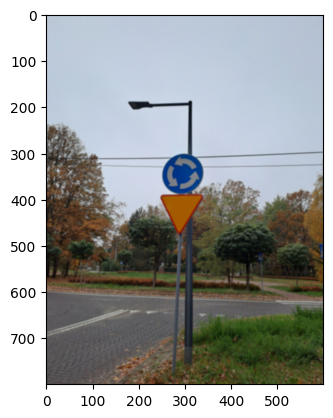

In [7]:
plt.imshow(cv2.cvtColor(przetworzone[9], cv2.COLOR_BGR2RGB))

## 3. Konwersja przestrzeni barw

In [8]:
hsv = []
for i in przetworzone:
  obraz = cv2.cvtColor(i,cv2.COLOR_BGR2HSV)
  hsv.append(obraz)

Dla wygody pracy pracy zrobię słownik znaków wraz z ich etykietami


In [9]:
obrazy_wg_etykiet = {
    "B-20": [],
    "C-12": [],
    "A-5": [],
    "Inny znak": []
}
for obraz,etykieta in zip(hsv,df_zdjecia["etykieta"]):
  if etykieta == "B-20":
    obrazy_wg_etykiet["B-20"].append(obraz)
  if etykieta == "C-12":
    obrazy_wg_etykiet["C-12"].append(obraz)
  if etykieta == "A-5":
    obrazy_wg_etykiet["A-5"].append(obraz)
  if etykieta == "Inny znak":
    obrazy_wg_etykiet["Inny znak"].append(obraz)

## 4. Segmentacja kolorów

### Defnicja przedziałów hsv

In [10]:
dolna_czerwien1 = np.array([0, 80, 50])
gorna_czerwien1 = np.array([10, 255, 255])

dolna_czerwien2 = np.array([170, 80, 50])
gorna_czerwien2 = np.array([179, 255, 255])

dolna_niebieski = np.array([105,  130, 50])
gorna_niebieski = np.array([110,  255, 255])

dolna_zolta = np.array([10, 100 , 70])
gorna_zolta = np.array([35,  255, 255])

### Maska niebieska - wizualizacja

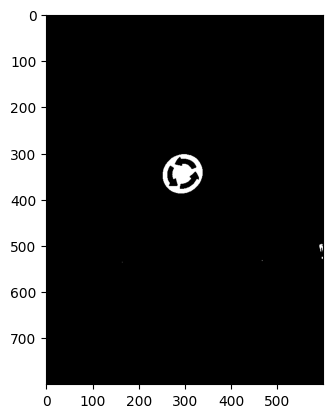

In [11]:
plt.imshow(cv2.inRange(hsv[9],dolna_niebieski,gorna_niebieski),cmap="gray")



### Maska czerwona - wizualizacja

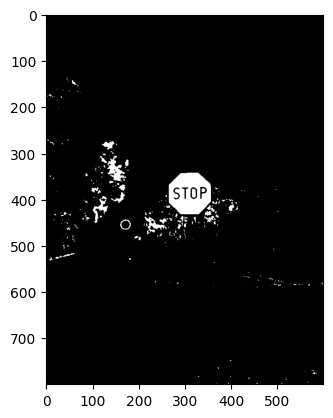

In [12]:
maska1 = cv2.inRange(hsv[0], dolna_czerwien1, gorna_czerwien1)
maska2 = cv2.inRange(hsv[0], dolna_czerwien2, gorna_czerwien2)

maska_czerwona = cv2.bitwise_or(maska1, maska2)

plt.imshow(maska_czerwona, cmap="gray")
plt.show()

### Maska żółta - wizualizacja

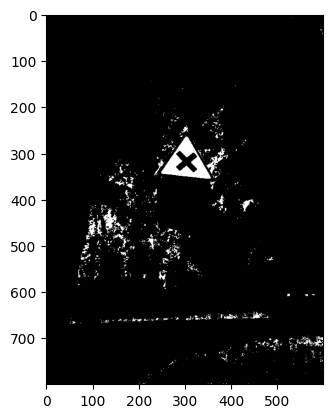

In [13]:
plt.imshow(cv2.inRange(hsv[20],dolna_zolta,gorna_zolta),cmap="gray")

### Generowanie masek

In [14]:
def tworzenie_masek(obraz):

  maska1 = cv2.inRange(obraz, dolna_czerwien1, gorna_czerwien1)
  maska2 = cv2.inRange(obraz, dolna_czerwien2, gorna_czerwien2)

  maska_czerwona = cv2.bitwise_or(maska1, maska2)

  maska_niebieska = cv2.inRange(obraz,dolna_niebieski,gorna_niebieski)

  maska_zolta = cv2.inRange(obraz,dolna_zolta,gorna_zolta)

  return maska_czerwona,maska_niebieska,maska_zolta

In [15]:
wszystkie_maski = []
for i in hsv:
  wszystkie_maski.append(tworzenie_masek(i))


## 5. Oczyszczanie masek

In [16]:
kernel_3 = np.ones((3, 3), dtype=np.uint8)
kernel_5 = np.ones((5, 5), dtype=np.uint8)
def oczyszczanie_maski(maska):
  maska = cv2.morphologyEx(maska,cv2.MORPH_OPEN,kernel_3)
  maska = cv2.morphologyEx(maska,cv2.MORPH_CLOSE,kernel_5)
  return maska

###Wizualizacja oczyszczonych masek

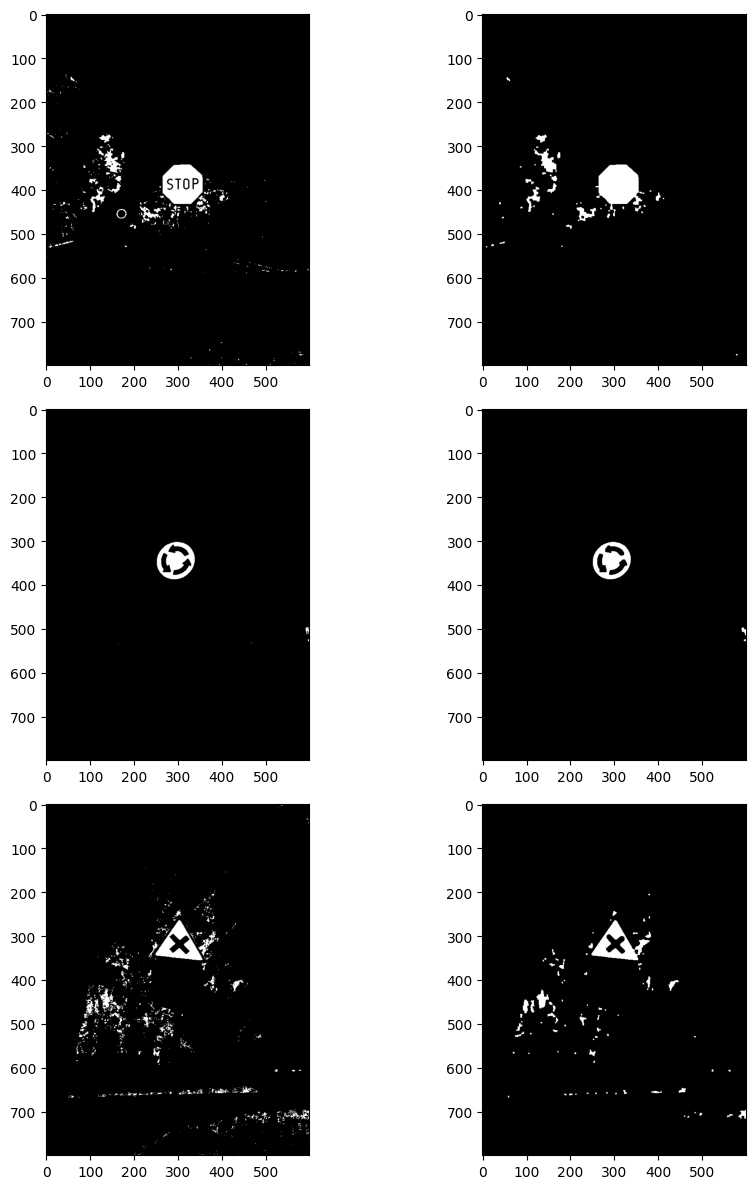

In [17]:
plt.figure(figsize=(10, 12))
plt.subplot(3,2,1)
plt.imshow(wszystkie_maski[0][0],cmap="gray")
plt.subplot(3,2,2)
plt.imshow(oczyszczanie_maski(wszystkie_maski[0][0]),cmap="gray")
plt.subplot(3,2,3)
plt.imshow(wszystkie_maski[9][1],cmap="gray")
plt.subplot(3,2,4)
plt.imshow(oczyszczanie_maski(wszystkie_maski[9][1]),cmap="gray")
plt.subplot(3,2,5)
plt.imshow(wszystkie_maski[20][2],cmap="gray")
plt.subplot(3,2,6)
plt.imshow(oczyszczanie_maski(wszystkie_maski[20][2]),cmap="gray")
plt.tight_layout()

### Oczyszczanie masek

In [18]:
wszystkie_maski_oczyszczone = []
for zestaw_masek in wszystkie_maski:
  maska_czerwona = oczyszczanie_maski(zestaw_masek[0])
  maska_niebieska = oczyszczanie_maski(zestaw_masek[1])
  maska_zolta = oczyszczanie_maski(zestaw_masek[2])
  wszystkie_maski_oczyszczone.append(
      [maska_czerwona, maska_niebieska, maska_zolta]
      )


## 6. Wykrywanie kandydatów / ROI

###Wykrywanie konturów oraz anliza ich powierzchni
Wykrywamy wszystkie kontury zewnętrzne a nastepnie usuwamy te których powierzchnia stanowi mniej niż 0,02% zdjęcia

In [19]:
kontury = []
for maski in wszystkie_maski_oczyszczone:
  kontur_czerwony,_ =  cv2.findContours(maski[0],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
  kontur_niebieski,_ =  cv2.findContours(maski[1],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
  kontur_zolty,_ =  cv2.findContours(maski[2],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

  # odsiewamy konury o powierzni miejszej niż 0,02% całej maski
  prog = maski[0].shape[0] * maski[0].shape[1] * 0.0002

  #konury z maski czerwonej
  kontury_czerwone_filtrowane = []
  for kontur in kontur_czerwony:
    if cv2.contourArea(kontur) >= prog:
      kontury_czerwone_filtrowane.append(kontur)
  #konury z maski niebieskiej
  kontury_niebieskie_filtrowane = []
  for kontur in kontur_niebieski:
    if cv2.contourArea(kontur) >= prog:
      kontury_niebieskie_filtrowane.append(kontur)
  #konury z maski zoltej
  kontury_zolte_filtrowane = []
  for kontur in kontur_zolty:
    if cv2.contourArea(kontur) >= prog:
      kontury_zolte_filtrowane.append(kontur)
  kontury.append(
      [kontury_czerwone_filtrowane,kontury_niebieskie_filtrowane,kontury_zolte_filtrowane]
  )


###Wizualizacja konturów po oczyszczeniu

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(800, 600), dtype=uint8)
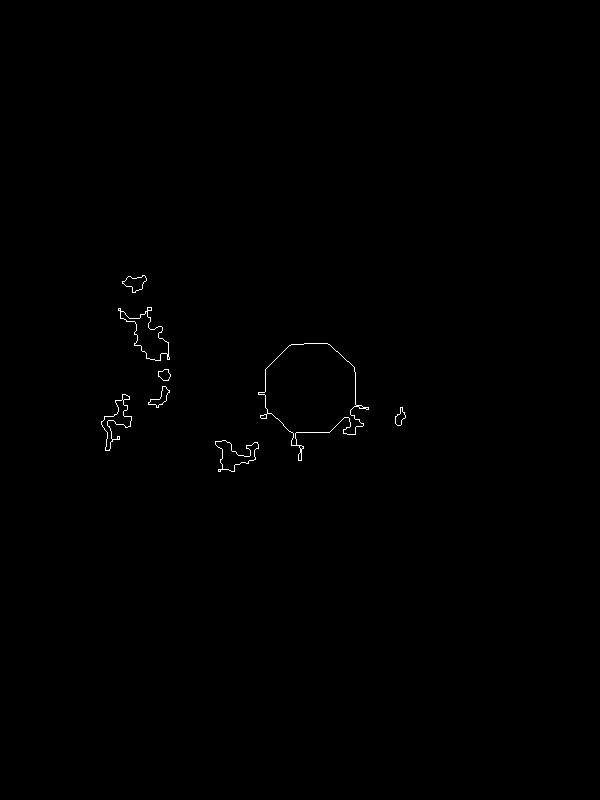

In [20]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[0][0])
cv2.drawContours(maska_po_filtracji,kontury[0][0],-1,(255,0,0),1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(800, 600), dtype=uint8)
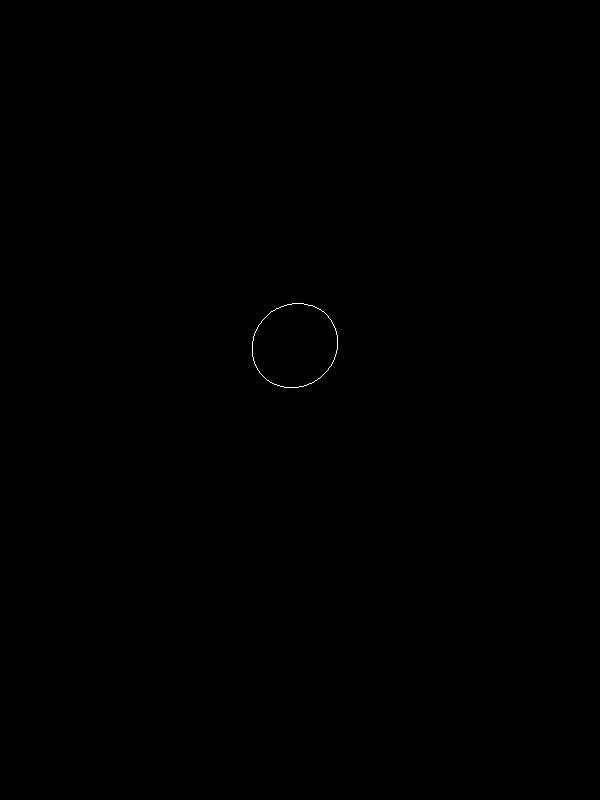

In [23]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[9][1])
cv2.drawContours(maska_po_filtracji,kontury[9][1],-1,(255,0,0),1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(800, 600), dtype=uint8)
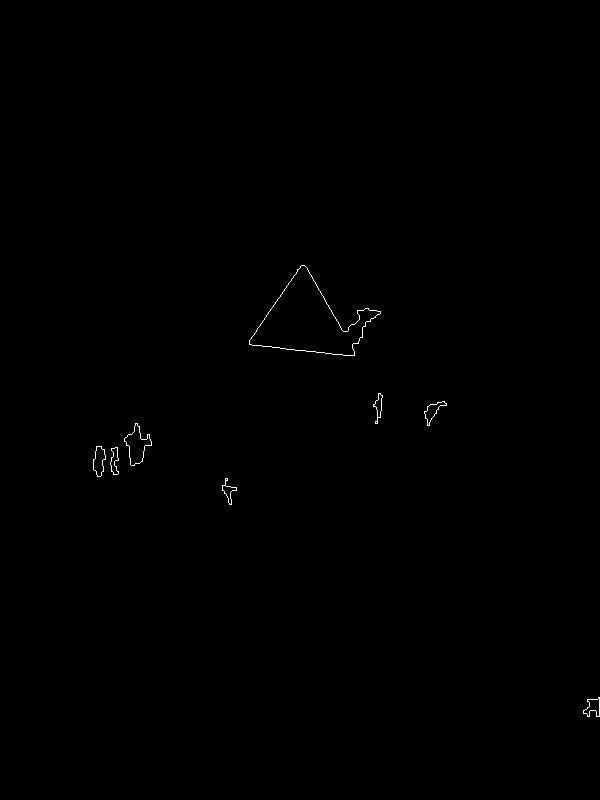

In [24]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[20][2])
cv2.drawContours(maska_po_filtracji,kontury[20][2],-1,(255,0,0),1)